# Spam & Ham — NLP Text Classification

## Innomatics Research Labs - Deep Learning Project

**Name:** SuryaPrabha Rebba  
**Enrollment Number:** 81010202726  
**Project Number:** Project 5  
**Domain:** NLP / Machine Learning / Deep Learning  

---

## Project Objective

The objective of this project is to develop an automated SMS spam detection
system capable of classifying incoming text messages as either:

- **Spam** — unwanted promotional, fraudulent, or scam messages
- **Ham** — legitimate non-spam messages

The project covers the complete NLP and Machine Learning pipeline including:

1. Exploratory Data Analysis
2. Data Cleaning
3. Text Preprocessing
4. Feature Engineering
5. TF-IDF Vectorization
6. Classical Machine Learning Models
7. Deep Learning NLP Architecture
8. Model Evaluation and Comparison
9. Model Deployment

## 1. Import Required Libraries

In this section, we import the libraries required for data manipulation,
visualization, NLP preprocessing, machine learning, and deep learning.

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Text processing
import re
import string

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_colwidth", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

Saving spam.csv to spam.csv


In [3]:
import os

print(os.listdir())

['.config', 'spam.csv', 'sample_data']


In [4]:
df = pd.read_csv("spam.csv", encoding="latin-1")

In [5]:
print(df.shape)
print(df.columns.tolist())
df.head()

(5572, 2)
['Category', 'Message']


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"



## Sprint 0 — Exploratory Data Analysis (EDA)

### Task 1: Understand the Data

**Objective:** Understand the structure and characteristics of the SMS Spam Collection dataset.

We will examine:
- Dataset dimensions
- Column names and data types
- Missing values
- Summary statistics
- Spam and ham message counts


In [6]:

print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe(include="all"))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nCategory Distribution:")
print(df["Category"].value_counts())

print("\nCategory Percentage:")
print(df["Category"].value_counts(normalize=True) * 100)


Dataset Shape: (5572, 2)

First 5 Records:


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5572 non-null   object
 1   Message   5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Summary Statistics:


,Category,Message
count,5572,5572
unique,2,5157
top,ham,"Sorry, I'll call later"
freq,4825,30



Missing Values:
Category    0
Message     0
dtype: int64

Category Distribution:
Category
ham     4825
spam     747
Name: count, dtype: int64

Category Percentage:
Category
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64



### Task 1 — Observations

1. The dataset contains 5,572 SMS messages with 2 columns:
   Category and Message.
2. Category is the target variable containing two labels:
   spam and ham.
3. Message contains the raw text of each SMS.
4. Both columns contain categorical/text data.
5. The dataset is imbalanced, with significantly more
   ham messages than spam messages.
6. Because of class imbalance, accuracy alone is not
   sufficient to evaluate model performance. Precision,
   recall, and F1-score will also be considered.



### Task 2: Define the Problem Statement

#### Business Problem

A telecommunications company is experiencing an increase
in unwanted SMS messages, including promotional content,
fraudulent offers, and scam attempts.

These spam messages negatively affect customer experience
and may expose users to financial fraud.

#### Project Objective

The objective is to develop an automated NLP-based SMS
classification system that predicts whether an incoming
message is Spam or Ham.

#### Key Questions

1. What percentage of messages are spam versus ham?
2. Are spam messages generally longer than ham messages?
3. Which words frequently appear in spam messages?
4. Do spam messages contain more digits and punctuation?
5. Can TF-IDF-based machine learning models accurately
   distinguish spam from ham?
6. Does a deep learning model such as LSTM outperform
   traditional machine learning models?

#### Proposed Solution

We will build an SMS spam classification pipeline using:

- Exploratory Data Analysis (EDA)
- Text preprocessing and feature engineering
- TF-IDF vectorization
- Multinomial Naive Bayes and Logistic Regression
- LSTM/Bi-LSTM deep learning architecture
- Model evaluation using precision, recall, F1-score,
  confusion matrix, and ROC-AUC
- Deployment using Streamlit

#### Expected Business Outcome

The system should identify spam messages accurately,
reduce unwanted messages, and help protect customers
while minimizing the risk of blocking legitimate SMS.





---


### Task 3: Data Cleaning and Manipulation

**Objective:** Improve the quality of the SMS Spam Collection
dataset before exploratory analysis and model development.

The following data cleaning operations will be performed:

1. Check for missing values.
2. Identify and remove duplicate records.
3. Check for empty or whitespace-only messages.
4. Standardize category labels.
5. Verify data types.
6. Generate a before-and-after cleaning report.

Data cleaning helps ensure reliable analysis, prevents
unnecessary duplicate observations, and reduces the
risk of misleading model evaluation.


In [7]:

# Create a working copy
df_clean = df.copy()

print("Original Dataset Shape:", df_clean.shape)

# Check missing values
print("\nMissing Values:")
print(df_clean.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

# Check duplicate message texts
print("\nDuplicate Message Texts:")
print(df_clean.duplicated(subset=["Message"]).sum())

# Check category values
print("\nUnique Categories:")
print(df_clean["Category"].unique())


Original Dataset Shape: (5572, 2)

Missing Values:
Category    0
Message     0
dtype: int64

Duplicate Rows:
415

Duplicate Message Texts:
415

Unique Categories:
['ham' 'spam']


In [8]:

# Record original number of rows
original_rows = len(df_clean)

# Remove records with missing Category or Message
df_clean = df_clean.dropna(
    subset=["Category", "Message"]
).copy()

# Standardize category labels
df_clean["Category"] = (
    df_clean["Category"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# Convert messages to strings and remove
# leading/trailing whitespace
df_clean["Message"] = (
    df_clean["Message"]
    .astype(str)
    .str.strip()
)

# Remove empty messages
df_clean = df_clean[
    df_clean["Message"] != ""
].copy()

# Check for unexpected categories
invalid_categories = df_clean[
    ~df_clean["Category"].isin(["spam", "ham"])
]

print("Invalid Category Records:", len(invalid_categories))

# Keep valid categories only
df_clean = df_clean[
    df_clean["Category"].isin(["spam", "ham"])
].copy()

# Check conflicting labels for identical SMS text
conflicts = df_clean.groupby("Message")["Category"].nunique()
conflicting_messages = conflicts[conflicts > 1]

print("Conflicting Message Labels:", len(conflicting_messages))

# Remove identical duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Reset index
df_clean = df_clean.reset_index(drop=True)

print("\nOriginal Rows:", original_rows)
print("Cleaned Rows:", len(df_clean))
print("Removed Rows:", original_rows - len(df_clean))
print("Cleaned Dataset Shape:", df_clean.shape)


Invalid Category Records: 0
Conflicting Message Labels: 0

Original Rows: 5572
Cleaned Rows: 5157
Removed Rows: 415
Cleaned Dataset Shape: (5157, 2)


In [9]:

print("Cleaned Dataset Information:")
df_clean.info()

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nRemaining Duplicate Rows:")
print(df_clean.duplicated().sum())

print("\nCategory Distribution:")
print(df_clean["Category"].value_counts())

print("\nFirst 5 Cleaned Records:")
display(df_clean.head())


Cleaned Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5157 entries, 0 to 5156
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Category  5157 non-null   object
 1   Message   5157 non-null   object
dtypes: object(2)
memory usage: 80.7+ KB

Missing Values:
Category    0
Message     0
dtype: int64

Remaining Duplicate Rows:
0

Category Distribution:
Category
ham     4516
spam     641
Name: count, dtype: int64

First 5 Cleaned Records:


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"



### Task 3 — Data Cleaning Observations

1. Original dataset contained 5,572 SMS messages.
2. No missing values were identified.
3. A total of 415 duplicate records were removed.
4. No invalid category values were found.
5. No conflicting labels were identified.
6. The cleaned dataset contains 5,157 records.
7. Ham messages: 4,516 (87.57%).
8. Spam messages: 641 (12.43%).
9. No duplicate records remain.

**Conclusion:**

Data cleaning successfully removed duplicate messages
while preserving valid SMS records.

The cleaned dataset contains 5,157 unique messages
and is ready for further exploratory analysis.

The dataset remains imbalanced, with ham messages
representing the majority of records.



### Task 4: Identify Data Types

**Objective:**

Identify the different types of variables in the
SMS Spam Collection dataset.

The dataset contains two original variables:

- Category: A nominal categorical variable representing
  spam or ham.
- Message: A text variable containing the SMS content.

Additional numerical features can be derived from the
message text to support exploratory analysis.



In [10]:

# Identify original column types

data_types = pd.DataFrame({
    "Column": df_clean.columns,
    "Pandas Data Type": df_clean.dtypes.astype(str).values,
    "Unique Values": df_clean.nunique().values,
    "Missing Values": df_clean.isnull().sum().values
})

display(data_types)

# Create a classification table

classification = pd.DataFrame({
    "Variable": ["Category", "Message"],
    "Variable Type": ["Nominal Categorical", "Text"],
    "Description": [
        "Discrete class label: Spam or Ham",
        "Raw SMS text with varying length and content"
    ]
})

display(classification)


,Column,Pandas Data Type,Unique Values,Missing Values
0,Category,object,2,0
1,Message,object,5157,0


,Variable,Variable Type,Description
0,Category,Nominal Categorical,Discrete class label: Spam or Ham
1,Message,Text,Raw SMS text with varying length and content



### Task 4 — Observations

1. The dataset contains two original variables:
   Category and Message.

2. Category is a nominal categorical variable with
   two possible values: spam and ham.

3. Message is a text variable containing raw SMS content.

4. The original dataset does not contain continuous
   numerical or ordinal variables.

5. Numerical features such as message length, word count,
   and punctuation count can be derived from Message.

6. These derived features can be analyzed to identify
   relationships with the target Category variable.

**Conclusion:**

The target variable is Category, and the primary input
feature is Message. Text feature engineering will help
identify characteristics that distinguish spam from ham.



### Task 5: Formulate Analysis Questions

**Objective:**

Identify meaningful questions that will help us understand
the characteristics of spam and ham SMS messages.

The following analysis questions will guide our EDA:

**Q1. What is the distribution of spam and ham messages?**

This helps identify class imbalance in the dataset.

**Q2. Are spam messages generally longer than ham messages?**

We will compare SMS character lengths using histograms
and descriptive statistics.

**Q3. Which words appear most frequently in spam and ham?**

We will use word frequency bar charts to identify
common words in both categories.

**Q4. Do spam messages contain more punctuation and digits?**

We will examine punctuation counts and digit counts
to identify differences in writing patterns.

**Q5. What are the most prominent words in spam and ham?**

We will create word clouds for both categories to
visualize commonly used terms.

**Q6. Is there a relationship between message length,
word count, punctuation count, and digit count?**

We will use correlation analysis and a heatmap to
understand relationships between numerical features.

**Q7. Can linguistic features help distinguish
spam messages from legitimate messages?**

We will summarize the EDA findings and examine
which features may be useful for classification.



### Task 6 Preparation: Feature Engineering for EDA

**Objective:**

Create meaningful numerical features from raw SMS text
to understand the differences between spam and ham messages.

The following features will be extracted:

1. message_length: Total number of characters, including spaces.
2. word_count: Total number of whitespace-separated words.
3. punctuation_count: Number of punctuation symbols.
4. digit_count: Number of numerical digits (0-9).

These features will be used to compare spam and ham
messages through statistical analysis and visualizations.

The original Message column will be preserved for
later NLP preprocessing and model development.


In [11]:
import string

# Create a separate DataFrame for EDA
df_eda = df_clean.copy()

# Feature 1: Message length (characters)
df_eda["message_length"] = df_eda["Message"].apply(len)

# Feature 2: Word count
df_eda["word_count"] = df_eda["Message"].apply(
    lambda text: len(text.split())
)

# Feature 3: Punctuation count
df_eda["punctuation_count"] = df_eda["Message"].apply(
    lambda text: sum(char in string.punctuation for char in text)
)

# Feature 4: Digit count
df_eda["digit_count"] = df_eda["Message"].apply(
    lambda text: sum(char.isdigit() for char in text)
)

print("Feature Engineering Completed!")
print("Dataset Shape:", df_eda.shape)

display(df_eda.head())


Feature Engineering Completed!
Dataset Shape: (5157, 6)


,Category,Message,message_length,word_count,punctuation_count,digit_count
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",111,20,9,0
1,ham,Ok lar... Joking wif u oni...,29,6,6,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,155,28,6,25
3,ham,U dun say so early hor... U c already then say...,49,11,6,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",61,13,2,0


In [12]:

# Select engineered numerical features
numeric_features = [
    "message_length",
    "word_count",
    "punctuation_count",
    "digit_count"
]

print("Overall Feature Statistics:")
display(df_eda[numeric_features].describe().round(2))

print("\nAverage Features by Category:")
display(
    df_eda.groupby("Category")[numeric_features]
    .mean()
    .round(2)
)


Overall Feature Statistics:


,message_length,word_count,punctuation_count,digit_count
count,5157.00,5157.00,5157.00,5157.00
mean,79.23,15.41,4.05,2.17
std,58.45,11.12,4.42,5.93
min,2.00,1.00,0.00,0.00
25%,36.00,7.00,1.00,0.00
50%,61.00,12.00,3.00,0.00
75%,118.00,22.00,5.00,1.00
max,910.00,171.00,133.00,40.00



Average Features by Category:


,message_length,word_count,punctuation_count,digit_count
Category,,,,
ham,70.95,14.24,3.83,0.30
spam,137.54,23.66,5.62,15.33


In [13]:

print("Final Dataset Shape:", df_eda.shape)

print("\nMissing Values:")
print(df_eda.isnull().sum())

print("\nFeature Data Types:")
print(df_eda.dtypes)

print("\nCategory Distribution:")
print(df_eda["Category"].value_counts())

print("\nSample Engineered Features:")
display(
    df_eda[
        [
            "Category",
            "message_length",
            "word_count",
            "punctuation_count",
            "digit_count"
        ]
    ].head(10)
)


Final Dataset Shape: (5157, 6)

Missing Values:
Category             0
Message              0
message_length       0
word_count           0
punctuation_count    0
digit_count          0
dtype: int64

Feature Data Types:
Category             object
Message              object
message_length        int64
word_count            int64
punctuation_count     int64
digit_count           int64
dtype: object

Category Distribution:
Category
ham     4516
spam     641
Name: count, dtype: int64

Sample Engineered Features:


,Category,message_length,word_count,punctuation_count,digit_count
0,ham,111,20,9,0
1,ham,29,6,6,0
2,spam,155,28,6,25
3,ham,49,11,6,0
4,ham,61,13,2,0
5,spam,148,32,8,4
6,ham,77,16,2,0
7,ham,160,26,6,1
8,spam,158,26,6,19
9,spam,154,29,2,13



### Step 9 — Feature Engineering Findings

The dataset contains 5,157 SMS messages and six columns
after feature engineering.

Key observations:

1. Spam messages are longer on average (137.54 characters)
   than ham messages (70.95 characters).

2. Spam messages contain more words on average
   (23.66 versus 14.24).

3. Average punctuation count is higher for spam
   (5.62) compared with ham (3.83).

4. Spam messages contain significantly more numerical
   digits (15.33) compared with ham messages (0.30).

5. The findings suggest that message length, word count,
   punctuation count, and digit count may be useful
   features for distinguishing spam from ham.

Conclusion:

Exploratory feature engineering reveals noticeable
differences between spam and ham messages, particularly
in message length and digit count. Further visualization
and modeling are needed to evaluate their usefulness.



### Task 6.1 — Spam vs Ham Class Distribution

**Objective:**

Visualize the distribution of spam and ham messages
in the cleaned SMS dataset.

This visualization helps identify class imbalance,
which can affect machine learning model performance.


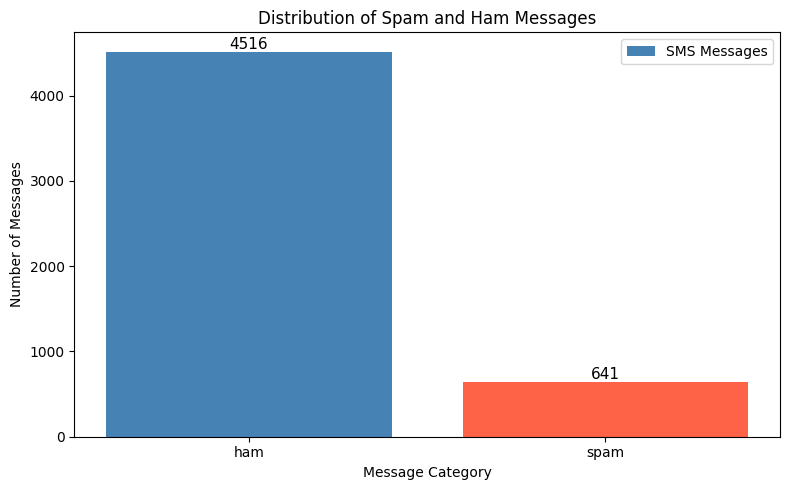


Category Percentages:
Category
ham     87.57
spam    12.43
Name: proportion, dtype: float64


In [14]:

# Count messages per category
category_counts = df_eda["Category"].value_counts()

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    category_counts.index,
    category_counts.values,
    color=["steelblue", "tomato"],
    label="SMS Messages"
)

# Display counts above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 30,
        str(int(height)),
        ha="center",
        fontsize=11
    )

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.legend()
plt.tight_layout()
plt.show()

# Display category percentages
print("\nCategory Percentages:")
print(
    (df_eda["Category"].value_counts(normalize=True) * 100)
    .round(2)
)



### Visualization 1 — Observations

The class distribution chart shows that the dataset
is highly imbalanced.

- Ham messages: 4,516 (87.57%)
- Spam messages: 641 (12.43%)

Ham messages significantly outnumber spam messages.

This imbalance is important because a model can achieve
high accuracy by predicting the majority class while
failing to identify spam.

Therefore, stratified train-test splitting will be used,
and model performance will be evaluated using precision,
recall, F1-score, and confusion matrices in addition
to accuracy.



### Visualization 2: Message Length Distribution

**Objective:**

Compare the distribution of message lengths between
spam and ham SMS messages using histograms.

**Approach:**

1. Separate spam and ham messages.
2. Use the engineered message_length feature.
3. Plot overlapping histograms for both categories.
4. Compare the average message lengths.
5. Identify differences in message length patterns.

**Analysis Question:**

Are spam messages generally longer than ham messages?



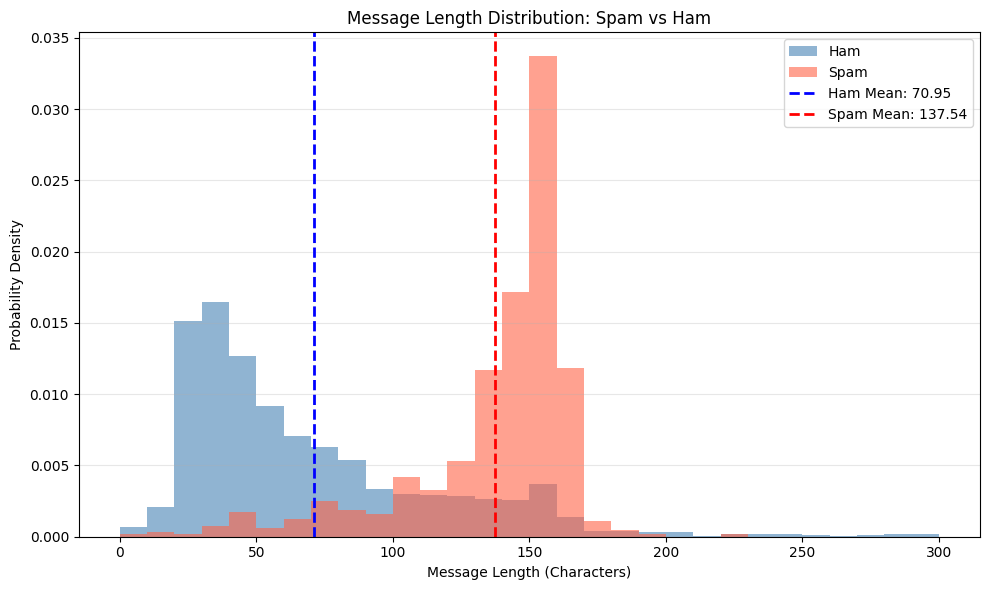

Ham Mean Length: 70.95
Spam Mean Length: 137.54

Ham Median Length: 53.0
Spam Median Length: 148.0

Ham Maximum Length: 910
Spam Maximum Length: 224

Messages Above 300 Characters:
Ham: 33
Spam: 0


In [15]:

# Separate spam and ham message lengths
ham_lengths = df_eda[
    df_eda["Category"] == "ham"
]["message_length"]

spam_lengths = df_eda[
    df_eda["Category"] == "spam"
]["message_length"]

# Create histogram
plt.figure(figsize=(10, 6))

# Common bins for both categories
bins = np.arange(0, 301, 10)

# Ham message distribution
plt.hist(
    ham_lengths,
    bins=bins,
    alpha=0.6,
    density=True,
    color="steelblue",
    label="Ham"
)

# Spam message distribution
plt.hist(
    spam_lengths,
    bins=bins,
    alpha=0.6,
    density=True,
    color="tomato",
    label="Spam"
)

# Add average message length lines
plt.axvline(
    ham_lengths.mean(),
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"Ham Mean: {ham_lengths.mean():.2f}"
)

plt.axvline(
    spam_lengths.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Spam Mean: {spam_lengths.mean():.2f}"
)

plt.title("Message Length Distribution: Spam vs Ham")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Print summary statistics
print("Ham Mean Length:", round(ham_lengths.mean(), 2))
print("Spam Mean Length:", round(spam_lengths.mean(), 2))

print("\nHam Median Length:", ham_lengths.median())
print("Spam Median Length:", spam_lengths.median())

print("\nHam Maximum Length:", ham_lengths.max())
print("Spam Maximum Length:", spam_lengths.max())

print("\nMessages Above 300 Characters:")
print("Ham:", (ham_lengths > 300).sum())
print("Spam:", (spam_lengths > 300).sum())



### Visualization 2 — Findings

The message length histogram reveals clear differences
between spam and ham SMS messages.

1. Average ham message length: 70.95 characters.
2. Average spam message length: 137.54 characters.
3. Median ham message length: 53 characters.
4. Median spam message length: 148 characters.
5. Maximum ham message length: 910 characters.
6. Maximum spam message length: 224 characters.
7. There are 33 ham messages longer than 300 characters,
   while no spam messages exceed 300 characters.

**Business Insight:**

Spam messages are generally longer than legitimate
messages, possibly because they include promotional
details, contact numbers, or instructions.

However, long legitimate messages also exist, and
the message length distributions overlap.

**Conclusion:**

Message length is a potentially useful predictive
feature but should not be used alone to classify SMS.



### Visualization 3: Top Word Frequency Analysis

**Objective:**

Identify the most frequently occurring words in spam
and ham messages.

**Approach:**

1. Separate spam and ham messages.
2. Convert text to lowercase.
3. Tokenize messages into words.
4. Remove common English stopwords.
5. Count word frequencies.
6. Visualize the top 15 words for each category.

This analysis helps identify common linguistic patterns
that may distinguish spam from legitimate messages.


In [16]:

import nltk
from nltk.corpus import stopwords
from collections import Counter
import re

# Download English stopwords
nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

print("Stopwords loaded:", len(stop_words))


Stopwords loaded: 198


In [17]:

def get_word_frequencies(messages):
    all_words = []

    for message in messages:
        # Convert to lowercase
        message = message.lower()

        # Extract alphabetic word tokens
        words = re.findall(r"[a-z]+", message)

        # Remove stopwords and single characters
        filtered_words = [
            word for word in words
            if word not in stop_words and len(word) > 1
        ]

        all_words.extend(filtered_words)

    return Counter(all_words)


# Separate messages by category
spam_messages = df_eda[
    df_eda["Category"] == "spam"
]["Message"]

ham_messages = df_eda[
    df_eda["Category"] == "ham"
]["Message"]

# Count word frequencies
spam_word_freq = get_word_frequencies(spam_messages)
ham_word_freq = get_word_frequencies(ham_messages)

print("Top 15 Spam Words:")
print(spam_word_freq.most_common(15))

print("\nTop 15 Ham Words:")
print(ham_word_freq.most_common(15))


Top 15 Spam Words:
[('call', 313), ('free', 192), ('txt', 139), ('ur', 119), ('stop', 115), ('text', 109), ('mobile', 107), ('reply', 96), ('claim', 94), ('www', 81), ('prize', 78), ('get', 70), ('cash', 64), ('new', 64), ('send', 59)]

Top 15 Ham Words:
[('get', 301), ('gt', 288), ('lt', 287), ('ok', 256), ('go', 248), ('got', 228), ('know', 226), ('like', 224), ('good', 217), ('come', 215), ('ur', 203), ('time', 193), ('call', 192), ('day', 191), ('love', 186)]


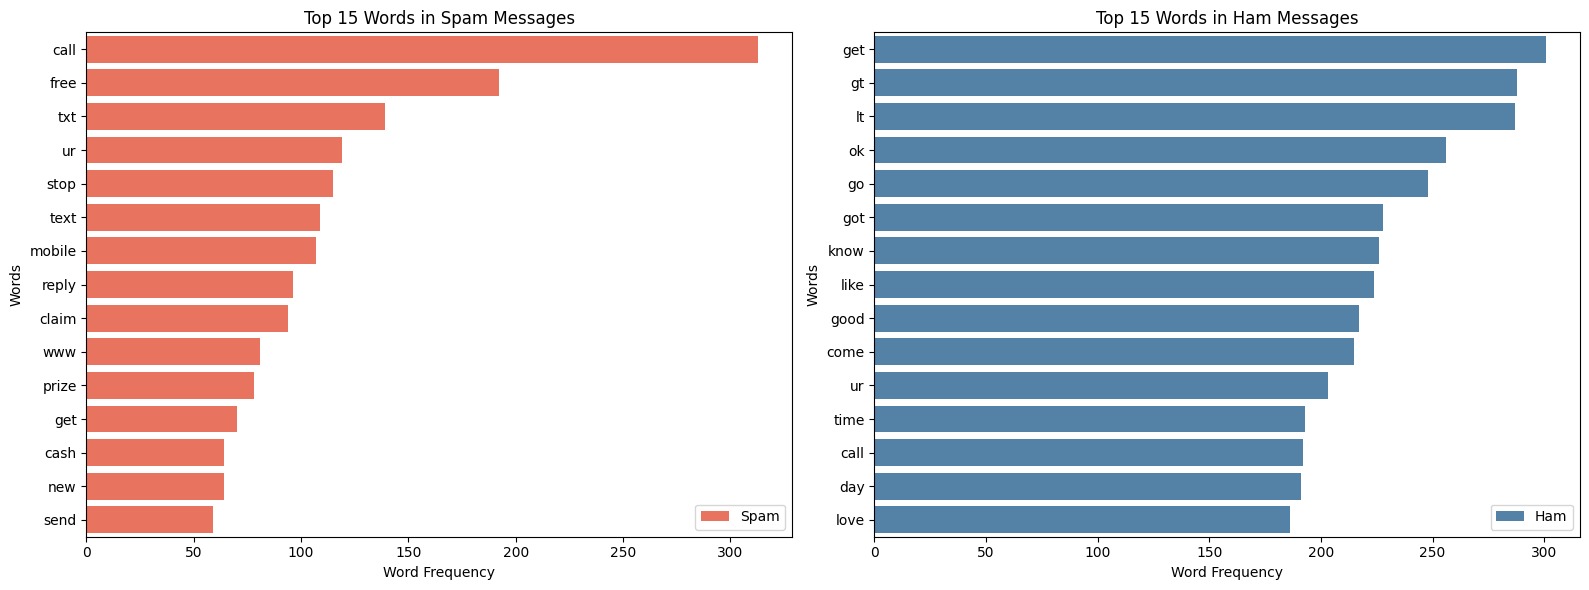

In [18]:

# Get top 15 words
top_spam = spam_word_freq.most_common(15)
top_ham = ham_word_freq.most_common(15)

# Create DataFrames
spam_df = pd.DataFrame(
    top_spam,
    columns=["Word", "Frequency"]
)

ham_df = pd.DataFrame(
    top_ham,
    columns=["Word", "Frequency"]
)

# Create two charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Spam words
sns.barplot(
    data=spam_df,
    x="Frequency",
    y="Word",
    color="tomato",
    ax=axes[0],
    label="Spam"
)

axes[0].set_title("Top 15 Words in Spam Messages")
axes[0].set_xlabel("Word Frequency")
axes[0].set_ylabel("Words")
axes[0].legend()

# Ham words
sns.barplot(
    data=ham_df,
    x="Frequency",
    y="Word",
    color="steelblue",
    ax=axes[1],
    label="Ham"
)

axes[1].set_title("Top 15 Words in Ham Messages")
axes[1].set_xlabel("Word Frequency")
axes[1].set_ylabel("Words")
axes[1].legend()

plt.tight_layout()
plt.show()



### Visualization 3 — Findings

The word frequency analysis reveals clear differences
in vocabulary between spam and ham SMS messages.

**Spam Messages:**

The most frequent spam words include:
- call (313)
- free (192)
- txt (139)
- ur (119)
- stop (115)
- text (109)
- mobile (107)
- reply (96)
- claim (94)
- www (81)

These words are commonly associated with promotional
offers, prize claims, and requests for user action.

**Ham Messages:**

The most frequent ham words include:
- get (301)
- gt (288)
- lt (287)
- ok (256)
- go (248)
- got (228)
- know (226)
- like (224)
- good (217)
- come (215)

These words mainly represent everyday communication.

**Business Insight:**

Spam messages frequently contain promotional and
action-oriented words such as free, claim, prize,
cash, and reply.

Ham messages generally contain conversational vocabulary.

However, some words appear in both categories,
so word frequency alone cannot accurately classify SMS.

**Conclusion:**

Word frequency analysis identifies useful linguistic
patterns that may support spam detection.

TF-IDF vectorization and machine learning models will
be used to evaluate these patterns further.



### Visualization 4 & 5: Spam and Ham Word Clouds

**Objective:**

Visualize the most frequently occurring words
in spam and ham SMS messages using word clouds.

**Approach:**

1. Use the word frequencies calculated previously.
2. Generate a separate word cloud for spam messages.
3. Generate another word cloud for ham messages.
4. Compare prominent vocabulary between the two classes.

Word clouds help visually identify important
linguistic patterns in SMS messages.


In [19]:

!pip -q install wordcloud

from wordcloud import WordCloud

print("WordCloud library imported successfully!")


WordCloud library imported successfully!


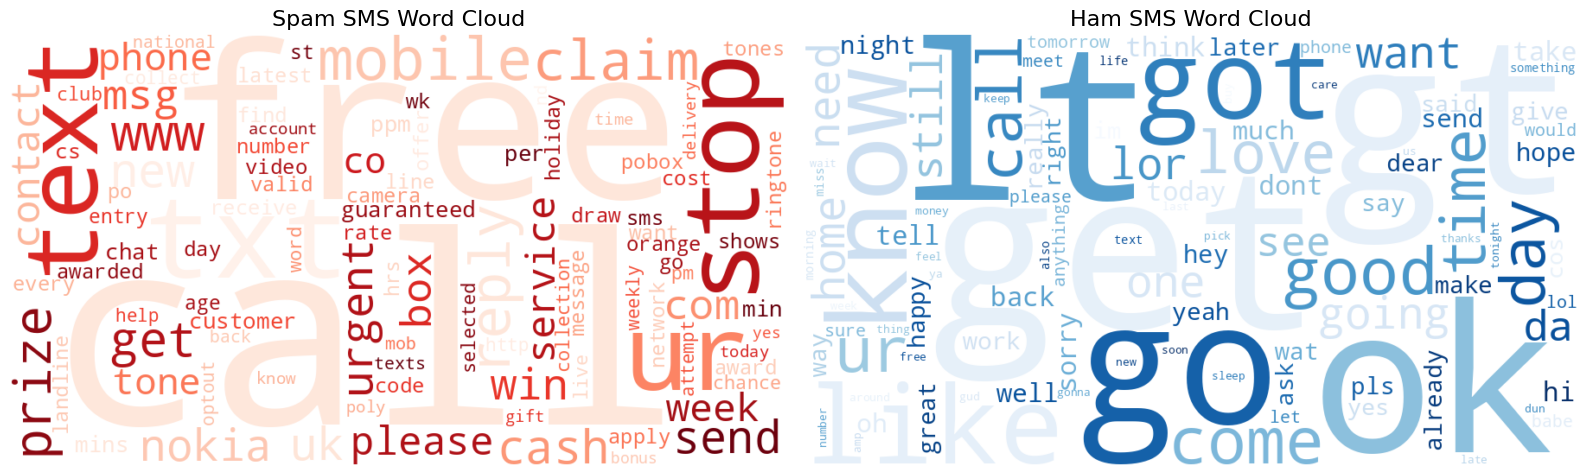

In [20]:

# Create spam word cloud
spam_wordcloud = WordCloud(
    width=900,
    height=500,
    background_color="white",
    colormap="Reds",
    max_words=100,
    random_state=42
).generate_from_frequencies(spam_word_freq)

# Create ham word cloud
ham_wordcloud = WordCloud(
    width=900,
    height=500,
    background_color="white",
    colormap="Blues",
    max_words=100,
    random_state=42
).generate_from_frequencies(ham_word_freq)

# Display word clouds
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(spam_wordcloud, interpolation="bilinear")
axes[0].set_title("Spam SMS Word Cloud", fontsize=16)
axes[0].axis("off")

axes[1].imshow(ham_wordcloud, interpolation="bilinear")
axes[1].set_title("Ham SMS Word Cloud", fontsize=16)
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [21]:

# Save word cloud images
spam_wordcloud.to_file("spam_wordcloud.png")
ham_wordcloud.to_file("ham_wordcloud.png")

print("Word clouds saved successfully!")


Word clouds saved successfully!



### Visualization 4 & 5 — Findings

The spam and ham word clouds reveal differences in
vocabulary between the two message categories.

**Spam Messages:**
Prominent words include free, call, txt, claim,
stop, mobile, prize, and cash.

These words suggest promotional content, prize
announcements, and calls to action.

**Ham Messages:**
Prominent words include got, go, know, like,
good, come, love, and time.

These words represent everyday conversations
and personal communication.

**Business Insight:**
Spam messages frequently contain marketing-related
and action-oriented vocabulary, while ham messages
tend to contain conversational vocabulary.

**Conclusion:**
Word frequency patterns provide useful exploratory
insights but are not sufficient for accurate spam
classification without machine learning.



### Visualization 6: Correlation Heatmap

**Objective:**

Analyze the relationships between numerical SMS
features and spam/ham classification.

**Approach:**

1. Convert the Category column into numerical labels.
2. Select the numerical features.
3. Calculate Pearson correlation coefficients.
4. Visualize relationships using a correlation heatmap.
5. Identify features associated with spam messages.

**Analysis Question:**

Which numerical SMS features have the strongest
correlation with the spam category?


In [22]:

# Create numerical target for EDA only
df_eda["spam_label"] = df_eda["Category"].map({
    "ham": 0,
    "spam": 1
})

print("Category Mapping:")
display(
    df_eda[["Category", "spam_label"]]
    .drop_duplicates()
    .sort_values("spam_label")
)

print("\nUpdated Dataset Shape:", df_eda.shape)


Category Mapping:


,Category,spam_label
0,ham,0
2,spam,1



Updated Dataset Shape: (5157, 7)


In [23]:

# Select numerical features
correlation_features = [
    "message_length",
    "word_count",
    "punctuation_count",
    "digit_count",
    "spam_label"
]

# Calculate Pearson correlation
correlation_matrix = df_eda[
    correlation_features
].corr(method="pearson")

print("Correlation Matrix:")
display(correlation_matrix.round(3))


Correlation Matrix:


,message_length,word_count,punctuation_count,digit_count,spam_label
message_length,1.000,0.974,0.621,0.377,0.376
word_count,0.974,1.000,0.575,0.281,0.280
punctuation_count,0.621,0.575,1.000,0.164,0.134
digit_count,0.377,0.281,0.164,1.000,0.836
spam_label,0.376,0.280,0.134,0.836,1.000


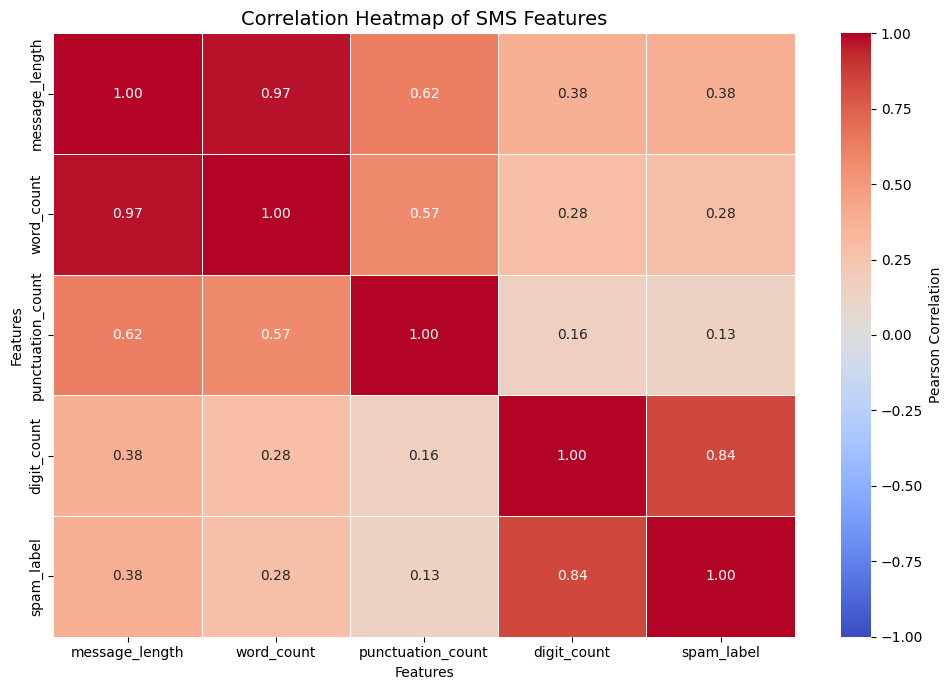

In [24]:

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title(
    "Correlation Heatmap of SMS Features",
    fontsize=14
)

plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


In [25]:

# Correlation of each feature with spam label
spam_correlations = (
    correlation_matrix["spam_label"]
    .drop("spam_label")
    .sort_values(ascending=False)
)

print("Feature Correlations with Spam:")
display(spam_correlations.round(3))


Feature Correlations with Spam:


,spam_label
digit_count,0.836
message_length,0.376
word_count,0.280
punctuation_count,0.134



### Visualization 6 — Correlation Heatmap Findings

The Pearson correlation heatmap reveals relationships
between numerical SMS features and spam classification.

**Key Findings:**

1. Digit count has the strongest positive correlation
   with spam_label (0.836).

2. Message length has a moderate positive correlation
   with spam_label (0.376).

3. Word count has a weak positive correlation
   with spam_label (0.280).

4. Punctuation count has a weak positive correlation
   with spam_label (0.134).

5. Message length and word count are highly correlated
   with each other (0.97).

**Business Insight:**

Numerical digits appear to be a strong distinguishing
characteristic of spam messages in this dataset.

This may be because spam messages frequently contain
phone numbers, promotional codes, and monetary amounts.

**Conclusion:**

Digit count and message length are potentially useful
features for SMS spam detection.

However, correlation does not prove causation or
guarantee predictive performance on unseen messages.



## Sprint 1 — Data Preprocessing

### Task 1: Train-Test Split

**Objective:**

Split the cleaned SMS dataset into training and testing
sets using an 80:20 ratio with stratification.

**Approach:**

1. Use the cleaned dataset containing 5,157 messages.
2. Set Message as the input feature (X).
3. Encode ham as 0 and spam as 1.
4. Split the dataset into 80% training and 20% testing.
5. Preserve the spam/ham class distribution using
   stratification.
6. Use random_state=42 for reproducibility.

**Reason:**

Stratified sampling ensures both training and test
datasets contain approximately the same proportions
of spam and ham messages.


In [26]:

from sklearn.model_selection import train_test_split

# Raw SMS messages
X = df_clean["Message"]

# Binary target: ham = 0, spam = 1
y = df_clean["Category"].map({
    "ham": 0,
    "spam": 1
})

# Split the dataset with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nTraining Percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting Percentages:")
print((y_test.value_counts(normalize=True) * 100).round(2))


Training Samples: 4125
Testing Samples: 1032

Training Class Distribution:
Category
0    3612
1     513
Name: count, dtype: int64

Testing Class Distribution:
Category
0    904
1    128
Name: count, dtype: int64

Training Percentages:
Category
0    87.56
1    12.44
Name: proportion, dtype: float64

Testing Percentages:
Category
0    87.6
1    12.4
Name: proportion, dtype: float64


In [27]:

# Check overlap between training and testing indices
overlap = set(X_train.index).intersection(set(X_test.index))

print("Overlapping Train/Test Indices:", len(overlap))

assert len(overlap) == 0
assert len(X_train) + len(X_test) == len(df_clean)

print("Train-test split verified successfully!")


Overlapping Train/Test Indices: 0
Train-test split verified successfully!



### Sprint 1 — Train-Test Split Observations

The cleaned dataset was divided into training and
testing subsets using an 80:20 stratified split.

- Training samples: 4,125
- Testing samples: 1,032
- Stratification preserved the class distribution.
- No training and testing row indices overlap.
- Random state 42 ensures reproducibility.

**Conclusion:**

The dataset is ready for text preprocessing and
vectorization. Learned transformations such as TF-IDF
and tokenizer vocabulary will be fitted only on the
training dataset to prevent data leakage.



### Sprint 1 — Task 1: NLP Text Preprocessing

**Objective:**

Transform raw SMS messages into standardized text
suitable for machine learning algorithms.

**Preprocessing Steps:**

1. Convert text to lowercase.
2. Remove URLs.
3. Remove punctuation marks.
4. Remove numerical digits.
5. Tokenize messages into words.
6. Remove common English stopwords.
7. Apply Porter stemming.
8. Join processed tokens into cleaned text.

**Important:**

We will preserve the original raw messages because
numerical digits, URLs, and punctuation may contain
important spam-detection signals.

The cleaned text will be used as a classical ML
baseline and compared with other approaches.


In [28]:

import nltk
import re
import string

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Download stopwords
nltk.download("stopwords", quiet=True)

# Initialize preprocessing tools
stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

print("NLP preprocessing libraries loaded successfully!")


NLP preprocessing libraries loaded successfully!


In [29]:

def preprocess_text(text):

    # Convert text to lowercase
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove punctuation and numerical digits
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenize using whitespace
    words = text.split()

    # Remove stopwords and apply stemming
    processed_words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words
    ]

    # Join words back into text
    return " ".join(processed_words)


print("Preprocessing function created!")


Preprocessing function created!


In [30]:

sample_messages = [
    "Congratulations! You WON $1000. Call 9876543210 now!!!",
    "Hey, are you coming to the office tomorrow?",
    "FREE entry! Visit www.example.com to claim your prize."
]

for message in sample_messages:
    print("Original:", message)
    print("Processed:", preprocess_text(message))
    print("-" * 60)


Original: Congratulations! You WON $1000. Call 9876543210 now!!!
Processed: congratul call
------------------------------------------------------------
Original: Hey, are you coming to the office tomorrow?
Processed: hey come offic tomorrow
------------------------------------------------------------
Original: FREE entry! Visit www.example.com to claim your prize.
Processed: free entri visit claim prize
------------------------------------------------------------


In [31]:

# Preprocess training messages
X_train_clean = X_train.apply(preprocess_text)

# Preprocess testing messages
X_test_clean = X_test.apply(preprocess_text)

print("Training Messages:", len(X_train_clean))
print("Testing Messages:", len(X_test_clean))

print("\nOriginal Training SMS:")
print(X_train.iloc[0])

print("\nPreprocessed Training SMS:")
print(X_train_clean.iloc[0])

print("\nOriginal Testing SMS:")
print(X_test.iloc[0])

print("\nPreprocessed Testing SMS:")
print(X_test_clean.iloc[0])


Training Messages: 4125
Testing Messages: 1032

Original Training SMS:
Saw Guys and Dolls last night with Patrick Swayze it was great

Preprocessed Training SMS:
saw guy doll last night patrick swayz great

Original Testing SMS:
Can you plz tell me the ans. BSLVYL sent via fullonsms.com

Preprocessed Testing SMS:
plz tell an bslvyl sent via fullonsm com


In [32]:

print("Missing Training Messages:", X_train_clean.isnull().sum())
print("Missing Testing Messages:", X_test_clean.isnull().sum())

print("\nEmpty Training Messages:")
print((X_train_clean.str.strip() == "").sum())

print("\nEmpty Testing Messages:")
print((X_test_clean.str.strip() == "").sum())

print("\nSample Processed Messages:")

display(
    pd.DataFrame({
        "Original": X_train.head(5).values,
        "Processed": X_train_clean.head(5).values
    })
)


Missing Training Messages: 0
Missing Testing Messages: 0

Empty Training Messages:
6

Empty Testing Messages:
1

Sample Processed Messages:


,Original,Processed
0,Saw Guys and Dolls last night with Patrick Swayze it was great,saw guy doll last night patrick swayz great
1,Nothing but we jus tot u would ask cos u ba gua... But we went mt faber yest... Yest jus went out already mah so today not going out... Jus call lor...,noth ju tot u would ask co u ba gua went mt faber yest yest ju went alreadi mah today go ju call lor
2,Oh really?? Did you make it on air? What's your talent?,oh realli make air talent
3,"TheMob>Hit the link to get a premium Pink Panther game, the new no. 1 from Sugababes, a crazy Zebra animation or a badass Hoody wallpaper-all 4 FREE!",themob hit link get premium pink panther game new sugabab crazi zebra anim badass hoodi wallpap free
4,"New Mobiles from 2004, MUST GO! Txt: NOKIA to No: 89545 & collect yours today! From ONLY Â£1. www.4-tc.biz 2optout 087187262701.50gbp/mtmsg18 TXTAUCTION.",new mobil must go txt nokia collect today optout gbp mtmsg txtauction



### Sprint 1 — Text Preprocessing Observations

Text preprocessing was applied separately to the
training and testing SMS messages.

The operations included:
- Lowercasing
- URL removal
- Punctuation removal
- Digit removal
- Tokenization
- Stopword removal
- Porter stemming

The original raw messages were preserved.

The processed training dataset contains 4,125 messages,
and the processed test dataset contains 1,032 messages.

**Conclusion:**

Text preprocessing has standardized SMS messages
for classical machine learning approaches.

However, since numerical digits showed a strong
correlation with spam during EDA, removing digits
may discard useful information.

Therefore, model evaluation should also consider
preserving numerical signals or adding engineered
features in later experiments.


In [33]:

# Preserve all rows and their existing train/test split

X_train_final = X_train_clean.mask(
    X_train_clean.str.strip() == "",
    "emptymsg"
)

X_test_final = X_test_clean.mask(
    X_test_clean.str.strip() == "",
    "emptymsg"
)

print("Empty Training Messages:",
      (X_train_final.str.strip() == "").sum())

print("Empty Testing Messages:",
      (X_test_final.str.strip() == "").sum())

print("Training Samples:", len(X_train_final))
print("Testing Samples:", len(X_test_final))


Empty Training Messages: 0
Empty Testing Messages: 0
Training Samples: 4125
Testing Samples: 1032



### Sprint 2 — TF-IDF Vectorization

**Objective:**

Convert preprocessed SMS messages into numerical
vectors using TF-IDF.

**Approach:**

1. Preserve all training and testing messages.
2. Replace empty processed messages with a placeholder.
3. Initialize TfidfVectorizer.
4. Fit the vectorizer on training messages only.
5. Transform both training and testing messages.
6. Verify the resulting feature matrix dimensions.

**Reason:**

Machine learning algorithms require numerical inputs.

TF-IDF captures the relative importance of words
and reduces the influence of frequently occurring
terms across the training corpus.

The vectorizer will be fitted only on training data
to prevent information leakage from the test set.


In [34]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

print("TF-IDF Vectorizer initialized!")


TF-IDF Vectorizer initialized!


In [35]:

# Learn vocabulary from training messages only
X_train_tfidf = tfidf.fit_transform(X_train_final)

# Apply same vocabulary to testing messages
X_test_tfidf = tfidf.transform(X_test_final)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("\nVocabulary Size:", len(tfidf.vocabulary_))

print("\nMatrix Type:", type(X_train_tfidf))


Training TF-IDF Shape: (4125, 5000)
Testing TF-IDF Shape: (1032, 5000)

Vocabulary Size: 5000

Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>


In [36]:

# Get learned vocabulary features
feature_names = tfidf.get_feature_names_out()

print("Total Vocabulary Features:", len(feature_names))

print("\nFirst 20 Features:")
print(feature_names[:20])

print("\nSample TF-IDF Vector:")
sample_vector = X_train_tfidf[0]

sample_weights = pd.DataFrame({
    "Word": feature_names[sample_vector.indices],
    "TF-IDF Weight": sample_vector.data
})

display(
    sample_weights
    .sort_values("TF-IDF Weight", ascending=False)
    .head(15)
)


Total Vocabulary Features: 5000

First 20 Features:
['aah' 'abiola' 'abl' 'abl pay' 'abt' 'ac' 'acc' 'accept' 'access' 'accid'
 'accordingli' 'account' 'account statement' 'ach' 'across' 'across sea'
 'act' 'action' 'activ' 'actual']

Sample TF-IDF Vector:


,Word,TF-IDF Weight
5,last night,0.474787
0,saw,0.466652
1,guy,0.394439
2,last,0.381344
4,great,0.361513
3,night,0.353716



### TF-IDF Vectorization — Observations

TF-IDF vectorization was applied to the preprocessed
training and testing SMS messages.

- Training messages: 4,125
- Testing messages: 1,032
- Maximum vocabulary features: 5,000
- Unigrams and bigrams were included.
- The vectorizer was fitted only on training data.
- Sparse matrices were generated for efficient storage.

Seven empty preprocessed messages were retained
using a special placeholder token.

**Conclusion:**

The SMS messages have been transformed into numerical
feature vectors suitable for classical machine learning
classification.

The resulting features will be used to train
Multinomial Naive Bayes and Logistic Regression models.



### Sprint 2 — Model 1: Multinomial Naive Bayes

**Objective:**

Train a Multinomial Naive Bayes classifier to identify
whether an SMS message is spam or ham.

**Approach:**

1. Import the MultinomialNB algorithm.
2. Initialize the classifier.
3. Train the model using training TF-IDF features.
4. Predict the categories of test SMS messages.
5. Calculate model performance using accuracy,
   precision, recall, and F1-score.

**Reason for choosing Naive Bayes:**

Multinomial Naive Bayes is computationally efficient,
works well with sparse text features, and provides
a baseline for comparing more advanced classifiers.


In [37]:

from sklearn.naive_bayes import MultinomialNB

# Initialize the Naive Bayes model
nb_model = MultinomialNB(alpha=1.0)

# Train using TF-IDF training features
nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes model trained successfully!")


Multinomial Naive Bayes model trained successfully!


In [38]:

# Predict categories on the test dataset
y_pred_nb = nb_model.predict(X_test_tfidf)

# Get predicted probabilities for spam (class 1)
y_prob_nb = nb_model.predict_proba(X_test_tfidf)[:, 1]

print("Predictions Generated:", len(y_pred_nb))

print("\nFirst 10 Predictions:")
print(y_pred_nb[:10])

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)


Predictions Generated: 1032

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 Actual Labels:
[0 0 0 0 0 0 0 0 0 0]


In [39]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate performance metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_precision = precision_score(
    y_test, y_pred_nb, zero_division=0
)
nb_recall = recall_score(
    y_test, y_pred_nb, zero_division=0
)
nb_f1 = f1_score(
    y_test, y_pred_nb, zero_division=0
)

print("Naive Bayes Model Performance")
print("-" * 40)

print(f"Accuracy  : {nb_accuracy:.4f}")
print(f"Precision : {nb_precision:.4f}")
print(f"Recall    : {nb_recall:.4f}")
print(f"F1 Score  : {nb_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


Naive Bayes Model Performance
----------------------------------------
Accuracy  : 0.9690
Precision : 1.0000
Recall    : 0.7500
F1 Score  : 0.8571

Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       904
        Spam       1.00      0.75      0.86       128

    accuracy                           0.97      1032
   macro avg       0.98      0.88      0.92      1032
weighted avg       0.97      0.97      0.97      1032



In [40]:

nb_results = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes"],
    "Accuracy": [nb_accuracy],
    "Precision": [nb_precision],
    "Recall": [nb_recall],
    "F1-Score": [nb_f1]
})

display(nb_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.969,1.0,0.75,0.8571



### Model 1 — Multinomial Naive Bayes Findings

The Multinomial Naive Bayes classifier was trained using
5,000 TF-IDF features.

**Evaluation Results:**

- Accuracy: 96.90%
- Spam Precision: 100.00%
- Spam Recall: 75.00%
- Spam F1-score: 85.71%

**Classification Results:**

- True Negatives: 904
- True Positives: 96
- False Positives: 0
- False Negatives: 32

**Business Insight:**

The model correctly identified all legitimate SMS
messages in the test set.

However, it failed to detect 32 out of 128 spam
messages, resulting in a spam recall of 75%.

**Conclusion:**

Naive Bayes provides a strong initial baseline with
excellent precision on the test dataset.

However, spam recall needs improvement to reduce
the number of unwanted messages reaching customers.

The next model, Logistic Regression, will be evaluated
on the same test dataset for comparison.



### Sprint 2 — Model 2: Logistic Regression

**Objective:**

Train a Logistic Regression classifier to predict
whether SMS messages are spam or ham.

**Approach:**

1. Initialize Logistic Regression.
2. Train using the same TF-IDF training features.
3. Generate predictions on the testing dataset.
4. Calculate accuracy, precision, recall, and F1-score.
5. Compare the results with Multinomial Naive Bayes.

**Reason for choosing Logistic Regression:**

Logistic Regression is an efficient classification
algorithm suitable for high-dimensional sparse
text features.

It provides a useful alternative to Naive Bayes
for SMS spam detection.


In [41]:

from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

# Train model
lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [42]:

# Predict categories
y_pred_lr = lr_model.predict(X_test_tfidf)

# Predicted probability for spam
y_prob_lr = lr_model.predict_proba(X_test_tfidf)[:, 1]

print("Predictions Generated:", len(y_pred_lr))

print("\nFirst 10 Predictions:")
print(y_pred_lr[:10])

print("\nFirst 10 Actual Labels:")
print(y_test.iloc[:10].values)


Predictions Generated: 1032

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 Actual Labels:
[0 0 0 0 0 0 0 0 0 0]


In [43]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(
    y_test, y_pred_lr, zero_division=0
)
lr_recall = recall_score(
    y_test, y_pred_lr, zero_division=0
)
lr_f1 = f1_score(
    y_test, y_pred_lr, zero_division=0
)

print("Logistic Regression Performance")
print("-" * 40)

print(f"Accuracy  : {lr_accuracy:.4f}")
print(f"Precision : {lr_precision:.4f}")
print(f"Recall    : {lr_recall:.4f}")
print(f"F1 Score  : {lr_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


Logistic Regression Performance
----------------------------------------
Accuracy  : 0.9700
Precision : 0.8647
Recall    : 0.8984
F1 Score  : 0.8812

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.98      0.98       904
        Spam       0.86      0.90      0.88       128

    accuracy                           0.97      1032
   macro avg       0.93      0.94      0.93      1032
weighted avg       0.97      0.97      0.97      1032



In [44]:

comparison_df = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression"
    ],
    "Accuracy": [
        nb_accuracy,
        lr_accuracy
    ],
    "Precision": [
        nb_precision,
        lr_precision
    ],
    "Recall": [
        nb_recall,
        lr_recall
    ],
    "F1-Score": [
        nb_f1,
        lr_f1
    ]
})

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.969,1.0000,0.7500,0.8571
1,Logistic Regression,0.970,0.8647,0.8984,0.8812



### Model 2 — Logistic Regression Findings

Logistic Regression was trained using 5,000 TF-IDF
features with balanced class weights.

**Evaluation Results:**

- Accuracy: 97.00%
- Spam Precision: 86.47%
- Spam Recall: 89.84%
- Spam F1-score: 88.12%

**Comparison with Naive Bayes:**

Logistic Regression achieved higher spam recall
(89.84% versus 75.00%) and a higher spam F1-score
(88.12% versus 85.71%).

It correctly identified 115 out of 128 spam messages,
whereas Naive Bayes detected 96.

However, Logistic Regression incorrectly classified
18 ham messages as spam, while Naive Bayes had zero
false positives on this test set.

**Business Insight:**

Logistic Regression is more effective at detecting
spam but introduces a greater risk of incorrectly
flagging legitimate SMS messages.

**Conclusion:**

Logistic Regression is currently the stronger baseline
based on spam recall and F1-score.

Further evaluation using confusion matrices, ROC-AUC,
and deep learning is required before final model selection.



### Sprint 2 — Task 2: Model Evaluation

**Objective:**

Evaluate Multinomial Naive Bayes and Logistic Regression
using confusion matrices and ROC-AUC curves.

**Approach:**

1. Calculate confusion matrices.
2. Identify true positives, true negatives,
   false positives, and false negatives.
3. Generate ROC curves for both models.
4. Calculate ROC-AUC scores.
5. Compare classification performance.

**Reason:**

Accuracy alone is insufficient for evaluating
imbalanced classification problems.

Confusion matrices help identify classification
errors, while ROC-AUC measures how well a model
ranks positive examples above negative examples
across different classification thresholds.


Naive Bayes Confusion Matrix:
[[904   0]
 [ 32  96]]

Logistic Regression Confusion Matrix:
[[886  18]
 [ 13 115]]


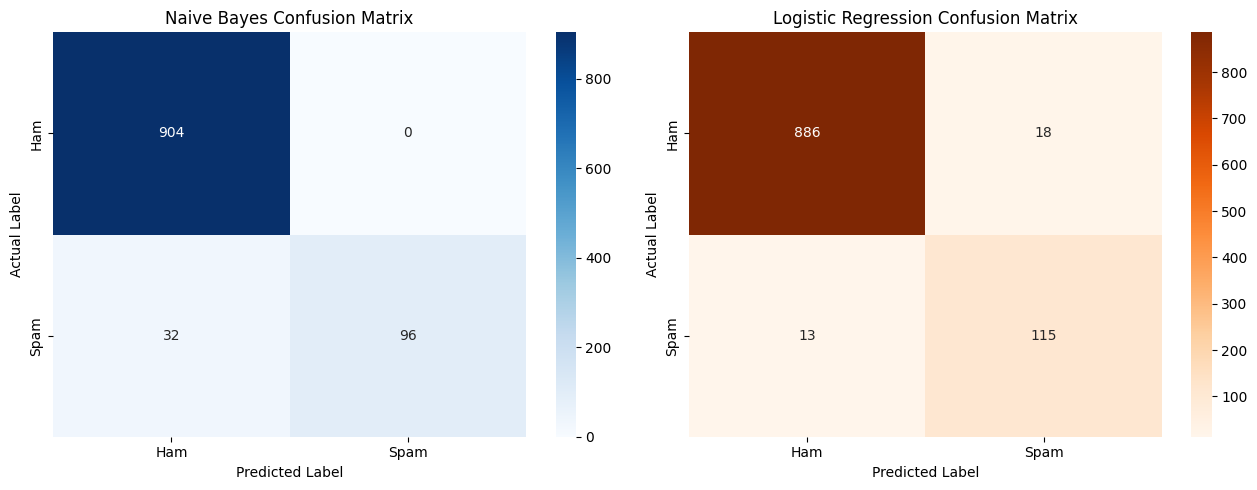

In [45]:

from sklearn.metrics import confusion_matrix

# Calculate confusion matrices
cm_nb = confusion_matrix(y_test, y_pred_nb, labels=[0, 1])
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])

# Display numerical confusion matrices
print("Naive Bayes Confusion Matrix:")
print(cm_nb)

print("\nLogistic Regression Confusion Matrix:")
print(cm_lr)

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    ax=axes[0]
)
axes[0].set_title("Naive Bayes Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"],
    ax=axes[1]
)
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


In [46]:

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# Calculate ROC-AUC
nb_auc = roc_auc_score(y_test, y_prob_nb)
lr_auc = roc_auc_score(y_test, y_prob_lr)

print(f"Naive Bayes ROC-AUC: {nb_auc:.4f}")
print(f"Logistic Regression ROC-AUC: {lr_auc:.4f}")

# Calculate ROC curve points
fpr_nb, tpr_nb, _ = roc_curve(y_test, y_prob_nb)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)


Naive Bayes ROC-AUC: 0.9809
Logistic Regression ROC-AUC: 0.9884


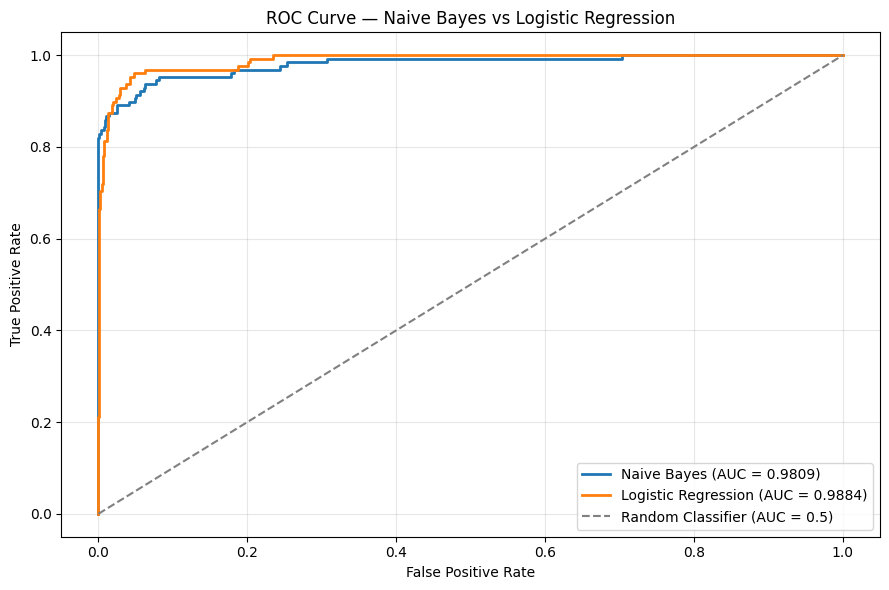

In [47]:

plt.figure(figsize=(9, 6))

plt.plot(
    fpr_nb,
    tpr_nb,
    linewidth=2,
    label=f"Naive Bayes (AUC = {nb_auc:.4f})"
)

plt.plot(
    fpr_lr,
    tpr_lr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {lr_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Naive Bayes vs Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [48]:

comparison_df = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression"
    ],
    "Accuracy": [nb_accuracy, lr_accuracy],
    "Precision": [nb_precision, lr_precision],
    "Recall": [nb_recall, lr_recall],
    "F1-Score": [nb_f1, lr_f1],
    "ROC-AUC": [nb_auc, lr_auc]
})

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Multinomial Naive Bayes,0.969,1.0000,0.7500,0.8571,0.9809
1,Logistic Regression,0.970,0.8647,0.8984,0.8812,0.9884



### Sprint 2 — Classical ML Evaluation Findings

Two classical machine learning models were developed:
Multinomial Naive Bayes and Logistic Regression.

**Naive Bayes:**
- Accuracy: 96.90%
- Precision: 100.00%
- Recall: 75.00%
- F1-score: 85.71%
- ROC-AUC: 0.9809
- False positives: 0
- False negatives: 32

**Logistic Regression:**
- Accuracy: 97.00%
- Precision: 86.47%
- Recall: 89.84%
- F1-score: 88.12%
- ROC-AUC: 0.9884
- False positives: 18
- False negatives: 13

**Business Insight:**

Logistic Regression detects more spam messages and
achieves higher recall, F1-score, and ROC-AUC.

Naive Bayes provides better spam precision and
avoids false positives in this test dataset.

**Conclusion:**

Logistic Regression is the stronger classical ML
baseline based on spam F1-score and recall.

The next phase will develop an LSTM deep learning
model and compare its performance with these
classical machine learning baselines.



## Sprint 3 — Deep Learning NLP Architecture

### Task 1: Develop an LSTM Model

**Objective:**

Develop a deep learning model to classify SMS messages
as spam or ham using Long Short-Term Memory (LSTM).

**Architecture:**

1. Text vectorization to convert text into sequences.
2. Embedding layer to learn word representations.
3. LSTM layer to learn sequential text patterns.
4. Dropout layer to reduce overfitting.
5. Dense output layer with sigmoid activation.

**Reason for choosing LSTM:**

LSTM networks can learn sequential dependencies
and contextual patterns in text.

The trained model will be compared with
Multinomial Naive Bayes and Logistic Regression
using the same test dataset.


In [49]:

import tensorflow as tf
from tensorflow.keras import layers, models

import numpy as np
import pandas as pd

# Reproducibility
tf.keras.utils.set_random_seed(42)

print("TensorFlow Version:", tf.__version__)
print("Keras Version:", tf.keras.__version__)

print("\nAvailable GPUs:")
print(tf.config.list_physical_devices("GPU"))


TensorFlow Version: 2.21.0
Keras Version: 3.13.2

Available GPUs:
[]


In [50]:

# Use raw SMS messages from the existing split
X_train_lstm = X_train.astype(str).values
X_test_lstm = X_test.astype(str).values

# Labels
y_train_lstm = y_train.to_numpy()
y_test_lstm = y_test.to_numpy()

print("Training Text Samples:", len(X_train_lstm))
print("Testing Text Samples:", len(X_test_lstm))

print("\nSample Training SMS:")
print(X_train_lstm[0])

print("\nSample Label:")
print(y_train_lstm[0])


Training Text Samples: 4125
Testing Text Samples: 1032

Sample Training SMS:
Saw Guys and Dolls last night with Patrick Swayze it was great

Sample Label:
0


In [51]:

# Configuration
MAX_TOKENS = 10000
SEQUENCE_LENGTH = 100

# Create text vectorization layer
vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode="int",
    output_sequence_length=SEQUENCE_LENGTH,
    standardize="lower_and_strip_punctuation"
)

# Learn vocabulary from training data only
vectorizer.adapt(X_train_lstm)

# Convert text to integer sequences
X_train_seq = vectorizer(
    tf.constant(X_train_lstm)
).numpy()

X_test_seq = vectorizer(
    tf.constant(X_test_lstm)
).numpy()

print("Vocabulary Size:", len(vectorizer.get_vocabulary()))
print("Training Sequence Shape:", X_train_seq.shape)
print("Testing Sequence Shape:", X_test_seq.shape)

print("\nFirst Training Sequence:")
print(X_train_seq[0][:30])


Vocabulary Size: 8460
Training Sequence Shape: (4125, 100)
Testing Sequence Shape: (1032, 100)

First Training Sequence:
[ 496  300    8 6851  160  112   36 5081 4134   15   60  121    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]


In [52]:

print("First Original Message:")
print(X_train_lstm[0])

print("\nFirst 30 Token IDs:")
print(X_train_seq[0][:30])

print("\nNon-padding Token Count:")
print(np.count_nonzero(X_train_seq[0]))

print("\nSequence Shape:", X_train_seq.shape)

assert X_train_seq.shape == (4125, 100)
assert X_test_seq.shape == (1032, 100)

print("\nSequence preparation verified!")


First Original Message:
Saw Guys and Dolls last night with Patrick Swayze it was great

First 30 Token IDs:
[ 496  300    8 6851  160  112   36 5081 4134   15   60  121    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0]

Non-padding Token Count:
12

Sequence Shape: (4125, 100)

Sequence preparation verified!



### LSTM Data Preparation — Observations

The original SMS messages were converted into
numerical sequences using Keras TextVectorization.

- Training messages: 4,125
- Testing messages: 1,032
- Maximum vocabulary size: 10,000
- Sequence length: 100 tokens

The vectorizer learned vocabulary from the training
dataset only to prevent data leakage.

Messages were converted into fixed-length numerical
sequences using padding and truncation.

The resulting sequences are suitable for use with
an Embedding layer and an LSTM neural network.



### Sprint 3 — LSTM Model Architecture and Training

**Objective:**

Develop a deep learning model using Long Short-Term
Memory (LSTM) to classify SMS messages as spam or ham.

**Architecture:**

1. Input Layer — Accepts sequences of 100 token IDs.
2. Embedding Layer — Converts tokens into 64-dimensional vectors.
3. LSTM Layer — Learns sequential patterns using 64 units.
4. Dropout Layer — Reduces overfitting.
5. Dense Output Layer — Predicts spam probability.

**Training Strategy:**

- Use the existing training dataset.
- Reserve 20% of training data for validation.
- Use binary cross-entropy loss.
- Use the Adam optimizer.
- Monitor validation loss using EarlyStopping.
- Evaluate performance on the untouched test dataset.

**Reason for choosing LSTM:**

LSTM can learn sequential dependencies and word-order
patterns that traditional TF-IDF models do not directly capture.


In [53]:

import tensorflow as tf
from tensorflow.keras import layers, models

# Clear previous models
tf.keras.backend.clear_session()

# Reproducibility
tf.keras.utils.set_random_seed(42)

VOCAB_SIZE = len(vectorizer.get_vocabulary())
EMBEDDING_DIM = 64

# Build LSTM model
lstm_model = models.Sequential([
    layers.Input(shape=(SEQUENCE_LENGTH,)),

    layers.Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    layers.LSTM(64),

    layers.Dropout(0.3),

    layers.Dense(
        1,
        activation="sigmoid"
    )
], name="SMS_Spam_LSTM")

# Compile model
lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

# Display architecture
lstm_model.summary()


Model: "SMS_Spam_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       541,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 574,529 (2.19 MB)

 Trainable params: 574,529 (2.19 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:

from sklearn.model_selection import train_test_split

X_lstm_train, X_lstm_val, y_lstm_train, y_lstm_val = (
    train_test_split(
        X_train_seq,
        y_train_lstm,
        test_size=0.20,
        random_state=42,
        stratify=y_train_lstm
    )
)

print("LSTM Training Samples:", len(X_lstm_train))
print("LSTM Validation Samples:", len(X_lstm_val))
print("Final Test Samples:", len(X_test_seq))

print("\nTraining Labels:")
print(np.bincount(y_lstm_train))

print("\nValidation Labels:")
print(np.bincount(y_lstm_val))


LSTM Training Samples: 3300
LSTM Validation Samples: 825
Final Test Samples: 1032

Training Labels:
[2890  410]

Validation Labels:
[722 103]


In [55]:

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

print("EarlyStopping configured successfully!")


EarlyStopping configured successfully!


In [56]:

history = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,

    validation_data=(
        X_lstm_val,
        y_lstm_val
    ),

    epochs=15,
    batch_size=32,

    callbacks=[early_stopping],

    verbose=1
)

print("\nLSTM Training Completed!")


Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 18s 125ms/step - accuracy: 0.9170 - loss: 0.2873 - precision: 0.8208 - recall: 0.4244 - val_accuracy: 0.9830 - val_loss: 0.0898 - val_precision: 0.9159 - val_recall: 0.9515
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 89ms/step - accuracy: 0.9885 - loss: 0.0511 - precision: 0.9721 - recall: 0.9341 - val_accuracy: 0.9770 - val_loss: 0.0750 - val_precision: 0.8500 - val_recall: 0.9903
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 140ms/step - accuracy: 0.9961 - loss: 0.0217 - precision: 0.9926 - recall: 0.9756 - val_accuracy: 0.9891 - val_loss: 0.0482 - val_precision: 0.9352 - val_recall: 0.9806
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 89ms/step - accuracy: 0.9979 - loss: 0.0085 - precision: 0.9903 - recall: 0.9927 - val_accuracy: 0.9903 - val_loss: 0.0415 - val_precision: 0.9524 - val_recall: 0.9709
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - accuracy: 0.9994 - loss: 0.0040 - precision: 0.9976 - recall: 0.9976 - val_accuracy: 0.9891 - val

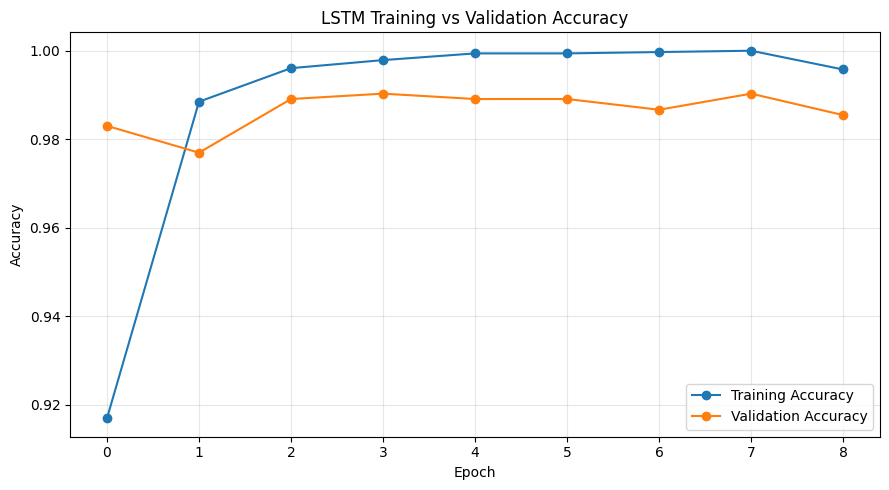

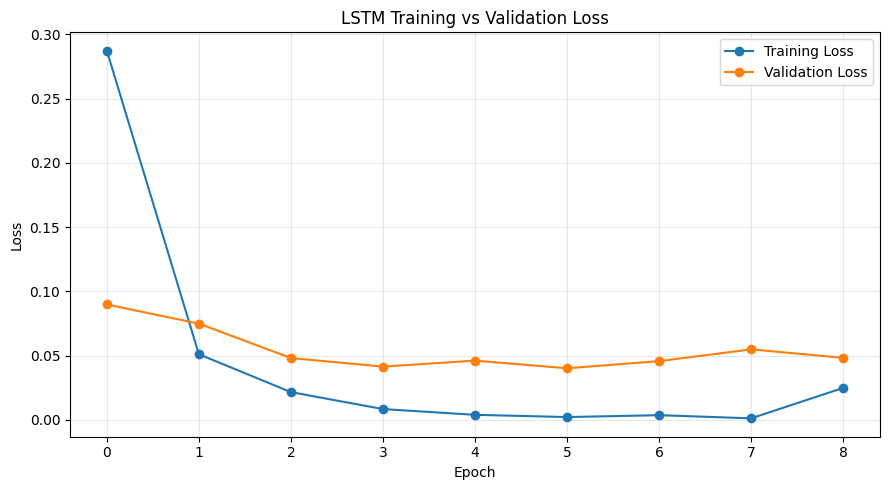

In [57]:

# Plot training and validation accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("LSTM Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot training and validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("LSTM Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [58]:

print("Epochs Completed:", len(history.history["loss"]))

print(
    "Final Training Accuracy:",
    round(history.history["accuracy"][-1], 4)
)

print(
    "Final Validation Accuracy:",
    round(history.history["val_accuracy"][-1], 4)
)

print(
    "Best Validation Loss:",
    round(min(history.history["val_loss"]), 4)
)

# Evaluate restored model on validation dataset
validation_results = lstm_model.evaluate(
    X_lstm_val,
    y_lstm_val,
    verbose=0,
    return_dict=True
)

print("\nRestored Model Validation Metrics:")
for metric, value in validation_results.items():
    print(f"{metric}: {value:.4f}")


Epochs Completed: 9
Final Training Accuracy: 0.9958
Final Validation Accuracy: 0.9855
Best Validation Loss: 0.0402

Restored Model Validation Metrics:
accuracy: 0.9891
loss: 0.0402
precision: 0.9700
recall: 0.9417



### Sprint 3 — LSTM Training Findings

An LSTM model was developed using TensorFlow and Keras.

**Architecture:**
- Vocabulary size: 8,460
- Embedding dimension: 64
- LSTM units: 64
- Dropout rate: 0.30
- Total trainable parameters: 574,529

**Training Configuration:**
- Training samples: 3,300
- Validation samples: 825
- Final test samples: 1,032
- Maximum epochs: 15
- EarlyStopping patience: 3

**Training Results:**
- Epochs completed: 9
- Best epoch: 6
- Best validation loss: 0.0402
- Restored validation accuracy: 98.91%
- Restored validation precision: 97.00%
- Restored validation recall: 94.17%

**Observations:**

The LSTM model learned rapidly, achieving very high
training accuracy.

Validation accuracy remained approximately 98–99%.

A small gap between training and validation performance
suggests possible overfitting.

EarlyStopping restored weights from epoch 6, which
achieved the lowest validation loss.

**Conclusion:**

The LSTM model demonstrated strong validation
performance and is ready for evaluation on the
reserved test dataset.



### Sprint 3 — Task 2: LSTM Model Evaluation

**Objective:**

Evaluate the trained LSTM model on the reserved
test dataset and compare its performance with
Multinomial Naive Bayes and Logistic Regression.

**Evaluation Metrics:**

1. Accuracy
2. Precision
3. Recall
4. F1-score
5. Confusion Matrix
6. ROC-AUC

**Approach:**

Use the same 1,032 test messages for all three models
to ensure a consistent evaluation dataset.

The test data was not used during model training
or EarlyStopping.


In [60]:

# Predict spam probabilities for test messages
y_prob_lstm = lstm_model.predict(
    X_test_seq,
    verbose=0
).ravel()

# Convert probabilities into predicted labels
# Spam if probability >= 0.5
y_pred_lstm = (y_prob_lstm >= 0.5).astype(int)

print("Total Test Predictions:", len(y_pred_lstm))

print("\nFirst 10 Predictions:")
print(y_pred_lstm[:10])

print("\nFirst 10 Actual Labels:")
print(y_test_lstm[:10])

print("\nFirst 10 Spam Probabilities:")
print(np.round(y_prob_lstm[:10], 4))


Total Test Predictions: 1032

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]

First 10 Actual Labels:
[0 0 0 0 0 0 0 0 0 0]

First 10 Spam Probabilities:
[0.0001 0.0075 0.0002 0.0001 0.0061 0.     0.0014 0.     0.0019 0.0018]


In [61]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score
)

# Calculate metrics
lstm_accuracy = accuracy_score(
    y_test_lstm, y_pred_lstm
)

lstm_precision = precision_score(
    y_test_lstm, y_pred_lstm,
    zero_division=0
)

lstm_recall = recall_score(
    y_test_lstm, y_pred_lstm,
    zero_division=0
)

lstm_f1 = f1_score(
    y_test_lstm, y_pred_lstm,
    zero_division=0
)

lstm_auc = roc_auc_score(
    y_test_lstm, y_prob_lstm
)

print("LSTM Model Performance")
print("-" * 40)

print(f"Accuracy  : {lstm_accuracy:.4f}")
print(f"Precision : {lstm_precision:.4f}")
print(f"Recall    : {lstm_recall:.4f}")
print(f"F1 Score  : {lstm_f1:.4f}")
print(f"ROC-AUC   : {lstm_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_lstm,
        y_pred_lstm,
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


LSTM Model Performance
----------------------------------------
Accuracy  : 0.9767
Precision : 0.9407
Recall    : 0.8672
F1 Score  : 0.9024
ROC-AUC   : 0.9881

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.99      0.99       904
        Spam       0.94      0.87      0.90       128

    accuracy                           0.98      1032
   macro avg       0.96      0.93      0.94      1032
weighted avg       0.98      0.98      0.98      1032



LSTM Confusion Matrix:
[[897   7]
 [ 17 111]]


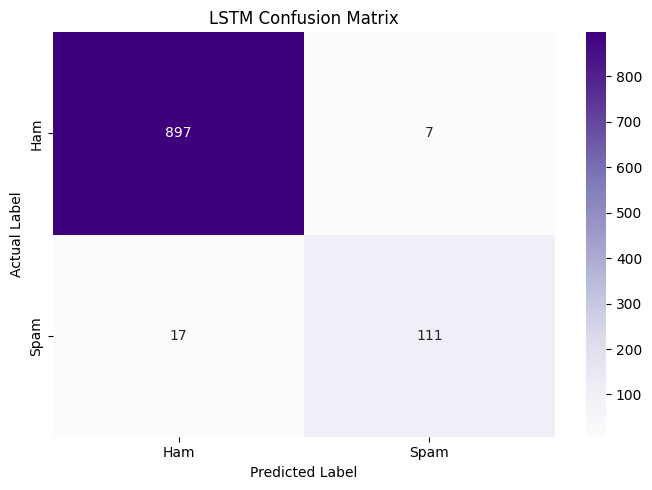

In [62]:

from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm_lstm = confusion_matrix(
    y_test_lstm,
    y_pred_lstm,
    labels=[0, 1]
)

print("LSTM Confusion Matrix:")
print(cm_lstm)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()


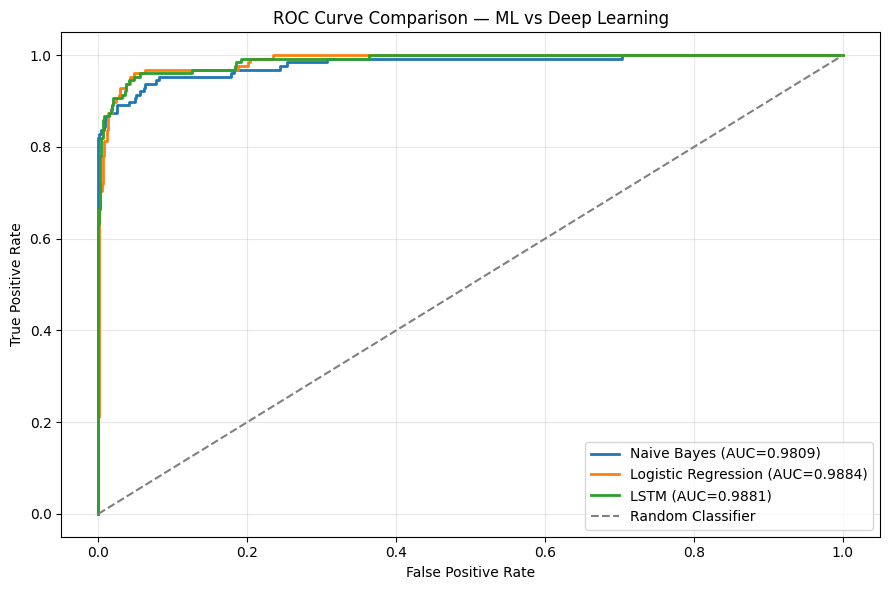

In [63]:

from sklearn.metrics import roc_curve

# LSTM ROC curve
fpr_lstm, tpr_lstm, _ = roc_curve(
    y_test_lstm,
    y_prob_lstm
)

plt.figure(figsize=(9, 6))

plt.plot(
    fpr_nb,
    tpr_nb,
    label=f"Naive Bayes (AUC={nb_auc:.4f})",
    linewidth=2
)

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC={lr_auc:.4f})",
    linewidth=2
)

plt.plot(
    fpr_lstm,
    tpr_lstm,
    label=f"LSTM (AUC={lstm_auc:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — ML vs Deep Learning")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [64]:

model_comparison = pd.DataFrame({
    "Model": [
        "Multinomial Naive Bayes",
        "Logistic Regression",
        "LSTM"
    ],

    "Accuracy": [
        nb_accuracy,
        lr_accuracy,
        lstm_accuracy
    ],

    "Precision": [
        nb_precision,
        lr_precision,
        lstm_precision
    ],

    "Recall": [
        nb_recall,
        lr_recall,
        lstm_recall
    ],

    "F1-Score": [
        nb_f1,
        lr_f1,
        lstm_f1
    ],

    "ROC-AUC": [
        nb_auc,
        lr_auc,
        lstm_auc
    ]
})

display(model_comparison.round(4))

print("\nHighest F1-Score:")
print(
    model_comparison.loc[
        model_comparison["F1-Score"].idxmax(),
        "Model"
    ]
)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Multinomial Naive Bayes,0.9690,1.0000,0.7500,0.8571,0.9809
1,Logistic Regression,0.9700,0.8647,0.8984,0.8812,0.9884
2,LSTM,0.9767,0.9407,0.8672,0.9024,0.9881



Highest F1-Score:
LSTM



### Sprint 3 — LSTM Model Evaluation Findings

Three SMS spam classification models were evaluated
using the same 1,032 test messages.

**LSTM Performance:**
- Accuracy: 97.67%
- Spam Precision: 94.07%
- Spam Recall: 86.72%
- Spam F1-score: 90.24%
- ROC-AUC: 0.9881

**LSTM Confusion Matrix:**
- True Negatives: 897
- False Positives: 7
- False Negatives: 17
- True Positives: 111

**Model Comparison:**

The LSTM model achieved the highest accuracy and
spam F1-score among all three models.

Logistic Regression achieved the highest spam
recall (89.84%) and ROC-AUC (0.9884).

Naive Bayes achieved perfect spam precision on
the test dataset but missed 32 spam messages.

**Business Insight:**

The LSTM model provides a strong balance between
spam detection and avoiding false positives.

It detected 111 of 128 spam messages while
incorrectly flagging only 7 legitimate messages.

**Conclusion:**

The LSTM model is selected for deployment because
it achieved the highest spam F1-score (90.24%)
and overall accuracy (97.67%) on the test dataset.

Further validation on newer and more diverse
messages would be needed before production use.



## Sprint 4 — Model Deployment

### Step 1: Save the Trained LSTM Model

**Objective:**

Save the trained LSTM model and its text vectorization
configuration for deployment.

**Approach:**

1. Save the LSTM model in Keras format.
2. Export the TextVectorization vocabulary.
3. Save the vectorization settings.
4. Verify that saved files exist.
5. Test loading and prediction consistency.

**Reason:**

Deployment requires the same trained model and text
processing configuration used during evaluation.


In [65]:

import json
import os

# Save trained LSTM
lstm_model.save("sms_spam_lstm.keras")

# Export vectorizer settings
vectorizer_config = {
    "vocabulary": vectorizer.get_vocabulary(),
    "max_tokens": MAX_TOKENS,
    "sequence_length": SEQUENCE_LENGTH,
    "standardize": "lower_and_strip_punctuation",
    "output_mode": "int"
}

# Save JSON
with open("sms_vectorizer_config.json", "w", encoding="utf-8") as f:
    json.dump(vectorizer_config, f, ensure_ascii=False, indent=2)

print("Model and vectorizer configuration saved!")

print("\nSaved Files:")
for filename in [
    "sms_spam_lstm.keras",
    "sms_vectorizer_config.json"
]:
    print(filename, os.path.getsize(filename), "bytes")


Model and vectorizer configuration saved!

Saved Files:
sms_spam_lstm.keras 6924744 bytes
sms_vectorizer_config.json 122917 bytes


In [66]:

from tensorflow.keras.models import load_model

# Load trained model
loaded_model = load_model("sms_spam_lstm.keras")

# Load vectorizer configuration
with open("sms_vectorizer_config.json", "r", encoding="utf-8") as f:
    loaded_config = json.load(f)

# Recreate text vectorizer
loaded_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=loaded_config["max_tokens"],
    output_mode=loaded_config["output_mode"],
    output_sequence_length=loaded_config["sequence_length"],
    standardize=loaded_config["standardize"]
)

# Restore vocabulary
loaded_vectorizer.set_vocabulary(
    loaded_config["vocabulary"]
)

# Test the same message
sample_sms = "Congratulations! You have won a free prize. Claim now!"

original_sequence = vectorizer(
    tf.constant([sample_sms])
)

loaded_sequence = loaded_vectorizer(
    tf.constant([sample_sms])
)

# Verify token sequences are identical
assert np.array_equal(
    original_sequence.numpy(),
    loaded_sequence.numpy()
)

# Compare predictions
original_prediction = lstm_model.predict(
    original_sequence,
    verbose=0
)[0][0]

loaded_prediction = loaded_model.predict(
    loaded_sequence,
    verbose=0
)[0][0]

print("Original Model Probability:", float(original_prediction))
print("Loaded Model Probability:", float(loaded_prediction))

assert np.isclose(
    original_prediction,
    loaded_prediction,
    atol=1e-5
)

print("\nModel reload validation successful!")


Original Model Probability: 0.9969823360443115
Loaded Model Probability: 0.9969823360443115

Model reload validation successful!


In [67]:

from google.colab import files

files.download("sms_spam_lstm.keras")
files.download("sms_vectorizer_config.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### Model Serialization — Observations

The selected LSTM model was saved in Keras format.

The TextVectorization vocabulary and configuration
were exported to JSON.

The saved artifacts include:
- sms_spam_lstm.keras
- sms_vectorizer_config.json

The saved model and vectorizer were reloaded and
tested for prediction consistency.

**Conclusion:**

The trained LSTM model and its preprocessing
configuration are ready for integration into
a Streamlit web application.



### Sprint 4 — Streamlit Application Development

A Streamlit application was developed to demonstrate
the trained LSTM SMS classification model.

**Features:**

1. SMS text input.
2. Spam/Ham prediction.
3. Model-estimated confidence score.
4. Spam probability indicator.
5. Message length, word count, and digit statistics.
6. Input validation and error handling.

**Deployment Architecture:**

User enters SMS text
        ↓
Streamlit application
        ↓
Saved TextVectorization vocabulary
        ↓
Trained LSTM model
        ↓
Spam probability and classification result

**Conclusion:**

The Streamlit application demonstrates how the
trained deep learning model can classify new SMS
messages without retraining the model.
